In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

--- Завантаження та перевірка структури ---
Загальна кількість записів: 299275

Типи даних та кількість пропусків по колонках:
                           Dtype  Missing Values  Missing %
oblast                       str               0       0.00
raion                        str          130235      43.52
hromada                      str          262486      87.71
level                        str               0       0.00
started_at   datetime64[us, UTC]               0       0.00
finished_at  datetime64[us, UTC]               0       0.00
source                       str               0       0.00

--- 1. Щільність даних (Часове покриття) ---
Дані охоплюють період: 2022-03-15 — 2026-09-07


C:\Users\slipko\AppData\Local\Temp\ipykernel_22436\4034557062.py:41: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['year_month'] = df['started_at'].dt.to_period('M')


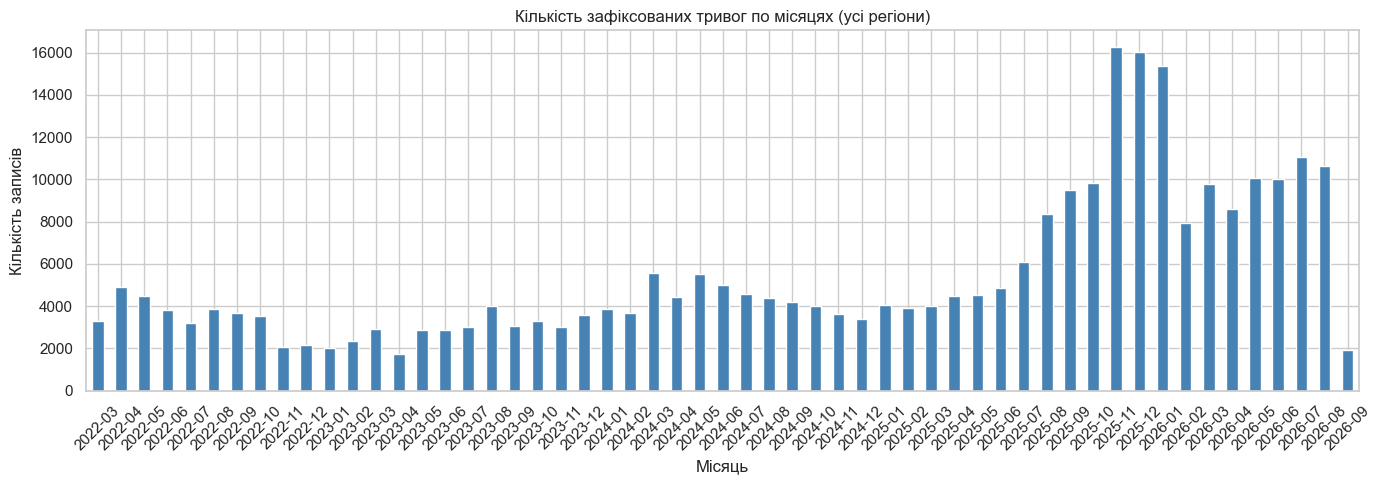


Записів з початку 2026 року: 85417
Розподіл по місяцях у 2026 році:
Month
1    15381
2     7922
3     9788
4     8609
5    10065
6    10006
7    11073
8    10636
9     1937
dtype: int64

--- 3. Ієрархія та узгодженість локацій ---
Кількість унікальних областей (oblast): 25
Записів із зазначеною 'hromada': 36789 (12.3%)

Патерни заповнення географічних даних:
   has_oblast  has_raion  has_hromada   count   pct
0        True      False        False  130235  43.5
1        True       True        False  132251  44.2
2        True       True         True   36789  12.3

Приклад ієрархії для 'Vinnytska oblast':
Знайдено районів: 6
  - Tulchynskyi raion (без громад)
  - Mohyliv-Podilskyi raion (без громад)
  - Khmilnytskyi raion (без громад)
  - Zhmerynskyi raion (без громад)
  - Vinnytskyi raion (без громад)


In [2]:
# Налаштування візуалізації
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

def load_and_inspect_raw_data(url="https://raw.githubusercontent.com/Vadimkin/ukrainian-air-raid-sirens-dataset/refs/heads/main/datasets/official_data_en.csv"):
    """Завантажує датасет та виводить базову статистику щодо пропусків."""
    print("--- Завантаження та перевірка структури ---")
    df = pd.read_csv(url, parse_dates=['started_at', 'finished_at'])
    
    print(f"Загальна кількість записів: {len(df)}")
    print("\nТипи даних та кількість пропусків по колонках:")
    
    # Створюємо таблицю з інформацією про пропуски
    missing_info = pd.DataFrame({
        'Dtype': df.dtypes,
        'Missing Values': df.isna().sum(),
        'Missing %': (df.isna().sum() / len(df) * 100).round(2)
    })
    print(missing_info)
    
    # Аналіз пропусків у часових мітках
    missing_finished = df['finished_at'].isna().sum()
    if missing_finished > 0:
        print(f"\nЗнайдено {missing_finished} записів без 'finished_at'.")
        # Дивимося, коли почалися ці незавершені тривоги
        unfinished_dates = df[df['finished_at'].isna()]['started_at'].dt.date.value_counts().head()
        print("Топ-5 дат з незавершеними тривогами:")
        print(unfinished_dates)
        
    return df

def analyze_data_density(df):
    """Аналізує кількість записів по місяцях (фокус на 2026 рік)."""
    print("\n--- 1. Щільність даних (Часове покриття) ---")
    
    min_date = df['started_at'].min()
    max_date = df['started_at'].max()
    print(f"Дані охоплюють період: {min_date.date()} — {max_date.date()}")
    
    # Групуємо кількість тривог по місяцях
    df['year_month'] = df['started_at'].dt.to_period('M')
    monthly_counts = df.groupby('year_month').size()
    
    # Візуалізація
    plt.figure(figsize=(14, 5))
    monthly_counts.plot(kind='bar', color='steelblue')
    plt.title("Кількість зафіксованих тривог по місяцях (усі регіони)")
    plt.xlabel("Місяць")
    plt.ylabel("Кількість записів")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    
    # Фокус на 2026 рік
    df_2026 = df[df['started_at'].dt.year >= 2026]
    print(f"\nЗаписів з початку 2026 року: {len(df_2026)}")
    if not df_2026.empty:
        print("Розподіл по місяцях у 2026 році:")
        print(df_2026.groupby(df_2026['started_at'].dt.month).size().rename_axis('Month'))

def analyze_hierarchy_and_hromadas(df):
    """Досліджує ієрархію локацій (oblast -> raion -> hromada) та англомовні назви."""
    print("\n--- 3. Ієрархія та узгодженість локацій ---")
    
    # Перевірка наявності базових колонок
    required_cols = ['oblast', 'raion', 'hromada']
    if not all(col in df.columns for col in required_cols):
        print(f"Помилка: відсутні колонки {required_cols}. Наявні: {df.columns.tolist()}")
        return
        
    unique_oblasts = df['oblast'].nunique()
    print(f"Кількість унікальних областей (oblast): {unique_oblasts}")
    
    # Оцінка наявності громад
    hromada_present = df['hromada'].notna().sum()
    hromada_pct = (hromada_present / len(df)) * 100
    print(f"Записів із зазначеною 'hromada': {hromada_present} ({hromada_pct:.1f}%)")
    
    # Дослідження структури: скільки рівнів заповнено одночасно
    print("\nПатерни заповнення географічних даних:")
    patterns = df.groupby(
        [df['oblast'].notna(), df['raion'].notna(), df['hromada'].notna()]
    ).size().reset_index(name='count')
    patterns.columns = ['has_oblast', 'has_raion', 'has_hromada', 'count']
    patterns['pct'] = (patterns['count'] / len(df) * 100).round(1)
    print(patterns)
    
    # Виводимо приклад ієрархії для однієї області (щоб побачити англійський неймінг)
    sample_oblast = df['oblast'].dropna().iloc[0]
    print(f"\nПриклад ієрархії для '{sample_oblast}':")
    
    # Відбираємо унікальні комбінації область-район-громада
    hierarchy = df[df['oblast'] == sample_oblast][['raion', 'hromada']].drop_duplicates()
    
    unique_raions = hierarchy['raion'].dropna().unique()
    print(f"Знайдено районів: {len(unique_raions)}")
    for raion in unique_raions[:5]: # Виводимо перші 5 районів
        hromadas_in_raion = hierarchy[hierarchy['raion'] == raion]['hromada'].dropna().tolist()
        hromada_str = f"({len(hromadas_in_raion)} громад)" if hromadas_in_raion else "(без громад)"
        print(f"  - {raion} {hromada_str}")

# ==========================================
# ВИКЛИК
# ==========================================
df_alerts = load_and_inspect_raw_data()
analyze_data_density(df_alerts)
analyze_hierarchy_and_hromadas(df_alerts)

In [3]:
print(sorted(df_alerts['oblast'].dropna().unique()))

['Cherkaska oblast', 'Chernihivska oblast', 'Chernivetska oblast', 'Dnipropetrovska oblast', 'Donetska oblast', 'Ivano-Frankivska oblast', 'Kharkivska oblast', 'Khersonska oblast', 'Khmelnytska oblast', 'Kirovohradska oblast', 'Kyiv City', 'Kyivska oblast', 'Luhanska oblast', 'Lvivska oblast', 'Mykolaivska oblast', 'Odeska oblast', 'Poltavska oblast', 'Rivnenska oblast', 'Sumska oblast', 'Ternopilska oblast', 'Vinnytska oblast', 'Volynska oblast', 'Zakarpatska oblast', 'Zaporizka oblast', 'Zhytomyrska oblast']


In [4]:
def remove_static_regions(df):
    """
    Видаляє регіони з постійною тривогою (константи) з датасету.
    """
    print("--- Видалення статичних регіонів ---")
    
    regions_to_remove = [
        'Luhanska oblast', 
    ]
    
    initial_count = len(df)
    
    # Фільтрація: залишаємо лише ті записи, де 'oblast' не входить до списку на видалення
    df_filtered = df[~df['oblast'].isin(regions_to_remove)].copy()
    
    removed_count = initial_count - len(df_filtered)
    
    print(f"Видалені регіони: {', '.join(regions_to_remove)}")
    print(f"Вилучено записів: {removed_count}")
    print(f"Залишилося записів для аналізу: {len(df_filtered)}")
    
    return df_filtered

# ==========================================
# ВИКЛИК У JUPYTER NOTEBOOK
# ==========================================
df_alerts_clean = remove_static_regions(df_alerts)

--- Видалення статичних регіонів ---
Видалені регіони: Luhanska oblast
Вилучено записів: 2
Залишилося записів для аналізу: 299273


In [5]:
def remove_micro_alerts(df, min_minutes=2):
    """
    Видаляє тривоги, тривалість яких менша за вказаний поріг.
    """
    print(f"--- Видалення мікротривог (< {min_minutes} хв) ---")
    
    initial_count = len(df)
    
    # Обчислюємо тривалість у хвилинах
    duration_mins = (df['finished_at'] - df['started_at']).dt.total_seconds() / 60.0
    
    # Фільтруємо
    df_filtered = df[duration_mins >= min_minutes].copy()
    
    removed_count = initial_count - len(df_filtered)
    
    print(f"Вилучено мікротривог: {removed_count}")
    print(f"Залишилося записів: {len(df_filtered)}")
    
    return df_filtered



In [6]:
def merge_oblast_intervals(df):
    """
    Об'єднує (зливає) пересічні інтервали тривог на рівні області.
    """
    print("--- 1. Злиття інтервалів на рівні областей ---")
    
    # Відкидаємо записи без області або без часу завершення
    df_clean = df.dropna(subset=['oblast', 'started_at', 'finished_at']).copy()
    
    # Сортуємо по області та часу початку для коректного алгоритму злиття
    df_clean = df_clean.sort_values(['oblast', 'started_at'])
    
    merged_records = []
    
    # Проходимо по кожній області окремо
    for oblast, group in df_clean.groupby('oblast'):
        current_start = None
        current_end = None
        
        for _, row in group.iterrows():
            start = row['started_at']
            end = row['finished_at']
            
            # Ініціалізація першого інтервалу
            if current_start is None:
                current_start = start
                current_end = end
            # Якщо поточна тривога починається до того, як закінчилася попередня -> злиття
            elif start <= current_end:
                current_end = max(current_end, end)
            # Якщо інтервали не перетинаються -> зберігаємо поточний і починаємо новий
            else:
                merged_records.append({
                    'oblast': oblast, 
                    'started_at': current_start, 
                    'finished_at': current_end
                })
                current_start = start
                current_end = end
                
        # Зберігаємо останній інтервал для області
        if current_start is not None:
            merged_records.append({
                'oblast': oblast, 
                'started_at': current_start, 
                'finished_at': current_end
            })
            
    df_merged = pd.DataFrame(merged_records)
    print(f"Кількість сирих записів: {len(df)}")
    print(f"Кількість унікальних епізодів після злиття: {len(df_merged)}")
    
    return df_merged

--- 1. Злиття інтервалів на рівні областей ---
Кількість сирих записів: 299273
Кількість унікальних епізодів після злиття: 80287
--- Видалення мікротривог (< 2 хв) ---
Вилучено мікротривог: 278
Залишилося записів: 80009

--- 2. Аналіз сезонності (Обласний рівень - Точний розподіл) ---
Розрізання інтервалів на межах місяців для точного підрахунку часу...


C:\Users\slipko\AppData\Local\Temp\ipykernel_22436\3525986783.py:52: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_merged['start_month'] = df_merged['started_at'].dt.to_period('M')
C:\Users\slipko\AppData\Local\Temp\ipykernel_22436\3525986783.py:57: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_split['month'] = df_split['started_at'].dt.to_period('M')


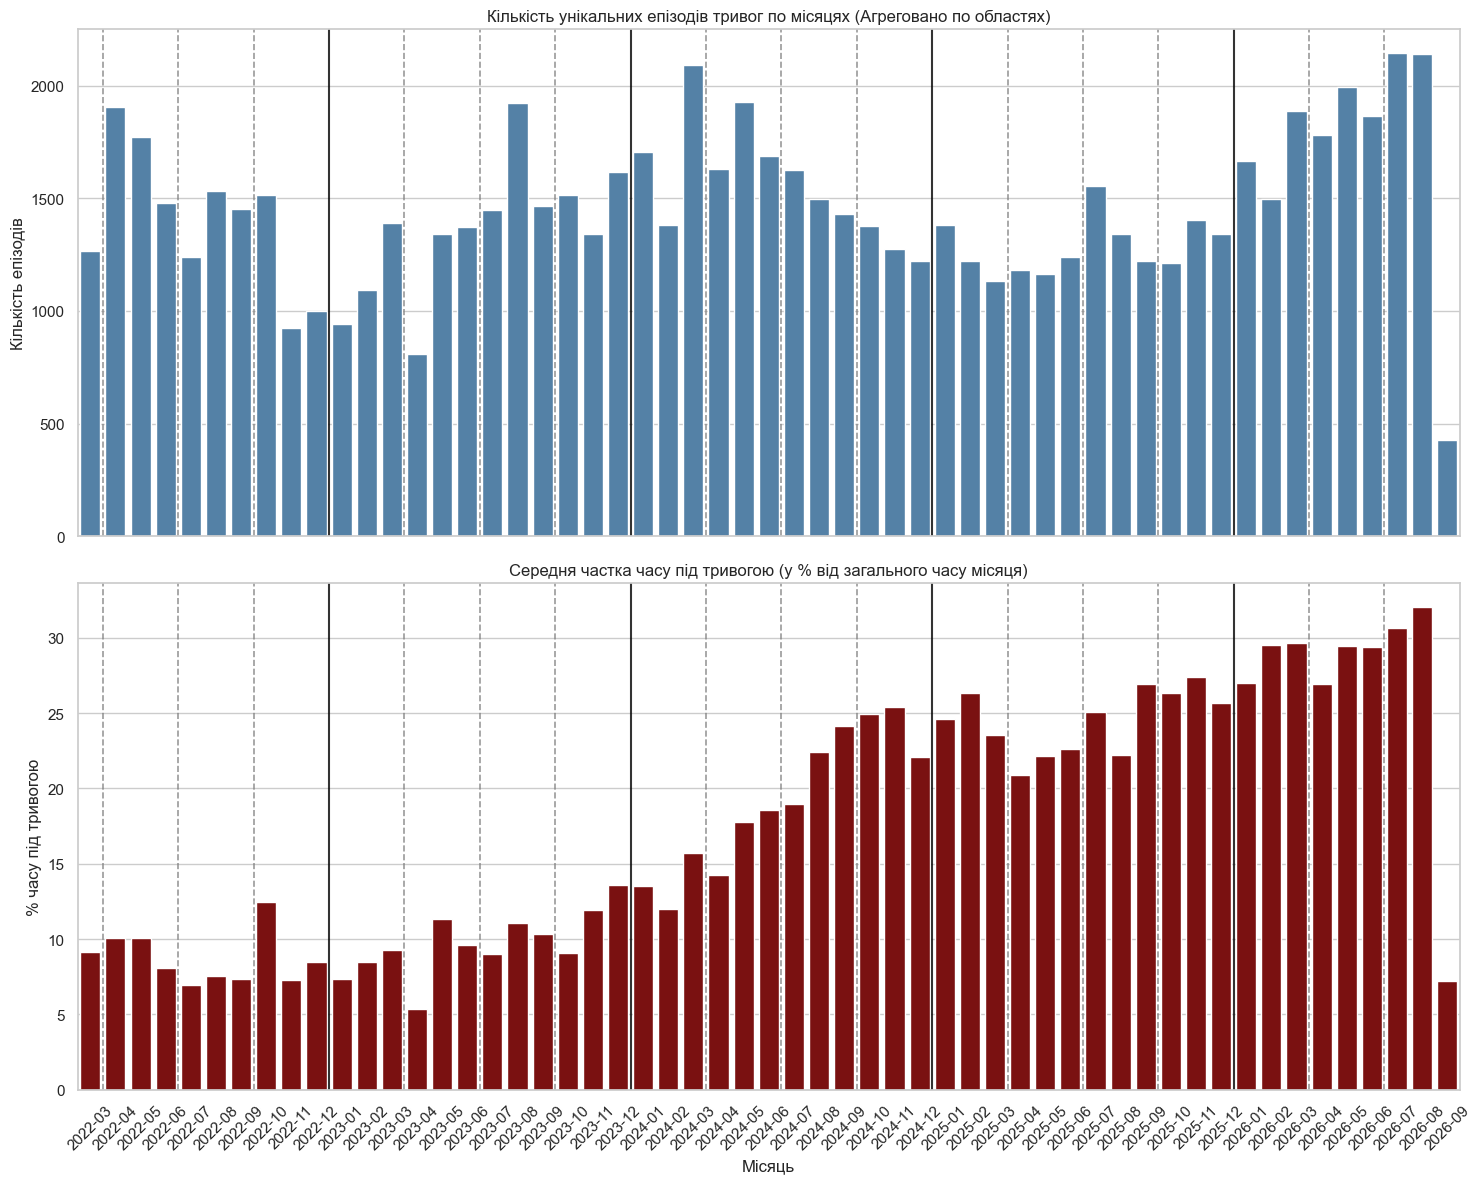

In [7]:
def split_intervals_by_month(df_merged):
    """
    Розрізає інтервали, які перетинають межі місяців, на окремі частини.
    """
    print("Розрізання інтервалів на межах місяців для точного підрахунку часу...")
    new_rows = []
    
    for _, row in df_merged.iterrows():
        start = row['started_at']
        end = row['finished_at']
        
        # Поки старт і кінець знаходяться в різних місяцях
        while (start.year != end.year) or (start.month != end.month):
            # Знаходимо початок наступного місяця відносно 'start'
            # (наприклад, для 2024-01-31 23:00 це буде 2024-02-01 00:00:00)
            next_month_start = (start.replace(day=1) + pd.DateOffset(months=1)).floor('D')
            
            # Якщо тривога завершується рівно о 00:00:00 1-го числа, 
            # while-цикл спрацює, але нам не треба створювати нульовий інтервал для нового місяця.
            if start == next_month_start:
                break
                
            # Додаємо частину, що належить поточному місяцю
            new_rows.append({
                'oblast': row['oblast'],
                'started_at': start,
                'finished_at': next_month_start
            })
            
            # Зсуваємо початок для наступної ітерації
            start = next_month_start
            
        # Додаємо залишок (або весь інтервал, якщо він не перетинав межу)
        if start < end:
            new_rows.append({
                'oblast': row['oblast'],
                'started_at': start,
                'finished_at': end
            })
            
    df_split = pd.DataFrame(new_rows)
    return df_split

def analyze_oblast_seasonality(df_merged):
    """
    Обчислює та візуалізує динаміку тривог із точним хронологічним розподілом
    та вертикальними лініями-маркерами для кварталів/років.
    """
    print("\n--- 2. Аналіз сезонності (Обласний рівень - Точний розподіл) ---")
    
    # 1. Підрахунок епізодів (без розрізання)
    df_merged['start_month'] = df_merged['started_at'].dt.to_period('M')
    episodes_count = df_merged.groupby('start_month').size().rename('episodes_count')
    
    # 2. Підрахунок часу (з розрізанням інтервалів)
    df_split = split_intervals_by_month(df_merged)
    df_split['month'] = df_split['started_at'].dt.to_period('M')
    df_split['duration_hrs'] = (df_split['finished_at'] - df_split['started_at']).dt.total_seconds() / 3600.0
    
    total_duration = df_split.groupby('month')['duration_hrs'].sum().rename('total_duration_hrs')
    
    # 3. Об'єднання метрик
    monthly_stats = pd.concat([episodes_count, total_duration], axis=1).fillna(0).reset_index()
    monthly_stats = monthly_stats.rename(columns={'index': 'year_month'})
    
    # Вираховуємо відсоток часу
    unique_oblasts_count = df_merged['oblast'].nunique()
    monthly_stats['year_month_str'] = monthly_stats['year_month'].astype(str)
    monthly_stats['days_in_month'] = monthly_stats['year_month'].dt.days_in_month
    
    # Максимально можливий сумарний час для всіх областей у цьому місяці
    max_possible_hrs = monthly_stats['days_in_month'] * 24 * unique_oblasts_count
    monthly_stats['pct_time_alert'] = (monthly_stats['total_duration_hrs'] / max_possible_hrs) * 100
    
    # Побудова графіків
    fig, axes = plt.subplots(2, 1, figsize=(15, 12), sharex=True)
    
    # Графік 1: Кількість епізодів
    sns.barplot(data=monthly_stats, x='year_month_str', y='episodes_count', color='steelblue', ax=axes[0])
    axes[0].set_title('Кількість унікальних епізодів тривог по місяцях (Агреговано по областях)')
    axes[0].set_ylabel('Кількість епізодів')
    axes[0].tick_params(axis='x', rotation=45)
    
    # Графік 2: Відсоток часу
    sns.barplot(data=monthly_stats, x='year_month_str', y='pct_time_alert', color='darkred', ax=axes[1])
    axes[1].set_title('Середня частка часу під тривогою (у % від загального часу місяця)')
    axes[1].set_xlabel('Місяць')
    axes[1].set_ylabel('% часу під тривогою')
    axes[1].tick_params(axis='x', rotation=45)
    
    # ДОДАВАННЯ ВЕРТИКАЛЬНИХ ЛІНІЙ
    # Використовуємо enumerate, щоб отримати позицію (i) кожного місяця на осі X.
    # Віднімаємо 0.5, щоб лінія проходила точно між стовпчиками (початок зазначеного місяця).
    for i, date_period in enumerate(monthly_stats['year_month']):
        month = date_period.month
        if month == 1:
            # Початок нового року (Січень) - суцільна лінія
            axes[0].axvline(i - 0.5, color='black', linestyle='-', linewidth=1.5, alpha=0.8)
            axes[1].axvline(i - 0.5, color='black', linestyle='-', linewidth=1.5, alpha=0.8)
        elif month in [4, 7, 10]:
            # Початок Квітня, Липня, Жовтня - пунктирна лінія
            axes[0].axvline(i - 0.5, color='gray', linestyle='--', linewidth=1.2, alpha=0.8)
            axes[1].axvline(i - 0.5, color='gray', linestyle='--', linewidth=1.2, alpha=0.8)
            
    plt.tight_layout()
    plt.show()

# ==========================================
# ВИКЛИК У JUPYTER NOTEBOOK
# ==========================================
# Припускаємо, що df_alerts — це сирий датасет
df_merged_oblasts = merge_oblast_intervals(df_alerts_clean)
df_merged_oblasts = remove_micro_alerts(df_merged_oblasts, min_minutes=2)
analyze_oblast_seasonality(df_merged_oblasts)

In [8]:
def analyze_durations(df):
    print("\n--- 3. Аналіз тривалості тривог ---")
    
    # Створюємо копію виключно для розрахунку тривалості (щоб не псувати оригінал)
    df_dur = df.dropna(subset=['finished_at']).copy()
    df_dur['duration_mins'] = (df_dur['finished_at'] - df_dur['started_at']).dt.total_seconds() / 60.0
    
    # Відкидаємо відверті аномалії парсера (напр. тривоги менше 10 секунд або більше 5 діб)
    df_dur = df_dur[(df_dur['duration_mins'] >= 0.5) & (df_dur['duration_mins'] <= 7200)]
    
    df_dur_2026 = df_dur[df_dur['started_at'].dt.year == 2026]
    slices = {"Весь період": df_dur, "2026 рік": df_dur_2026}
    
    stats_list = []
    for name, data in slices.items():
        if data.empty:
            continue
            
        dur = data['duration_mins']
        stats_list.append({
            'Період': name,
            'Мін (хв)': dur.min(),
            'Макс (хв)': dur.max(),
            'Середнє': dur.mean(),
            'Медіана': dur.median(),
            'Std Відхил': dur.std(),
            '10% квант.': dur.quantile(0.10),
            '25% квант.': dur.quantile(0.25),
            '75% квант.': dur.quantile(0.75),
            '90% квант.': dur.quantile(0.90)
        })
    
    stats_df = pd.DataFrame(stats_list).set_index('Період').round(1)
    print(stats_df)
    
    # Візуалізація: Boxplot
    df_dur['period_label'] = np.where(df_dur['started_at'].dt.year == 2026, '2026 рік', 'До 2026 року')
    
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=df_dur, x='duration_mins', y='period_label', hue='period_label', palette='Set2')
    plt.title("Розподіл тривалості тривог (у хвилинах)")
    plt.xlabel("Тривалість (хвилини)")
    plt.ylabel("")
    # Обмежуємо вісь X до 300 хвилин (5 годин) для читабельності графіку, бо довгі хвости стискають бокс
    plt.xlim(0, 300) 
    plt.tight_layout()
    plt.show()

def analyze_temporal_dynamics(df):
    print("\n--- 4. Часова динаміка та регулярність (Нормалізована) ---")
    
    df_temp = df.copy()
    df_temp['hour'] = df_temp['started_at'].dt.hour
    df_temp['day_of_week'] = df_temp['started_at'].dt.dayofweek # 0=Пн, 6=Нд
    
    df_2026 = df_temp[df_temp['started_at'].dt.year == 2026]
    
    # Створюємо кростаблиці з нормалізацією по всьому масиву (в сумі = 1) і переводимо у відсотки
    heatmap_all = pd.crosstab(df_temp['day_of_week'], df_temp['hour'], normalize='all') * 100
    
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    
    if not df_2026.empty:
        heatmap_2026 = pd.crosstab(df_2026['day_of_week'], df_2026['hour'], normalize='all') * 100
        
        # Визначаємо спільний максимум для однакової кольорової шкали на обох графіках
        global_vmax = max(heatmap_all.max().max(), heatmap_2026.max().max())
        
        # Графік 1: Весь період
        sns.heatmap(heatmap_all, cmap="YlOrRd", ax=axes[0], vmin=0, vmax=global_vmax, 
                    cbar_kws={'label': '% від усіх тривог періоду'})
        axes[0].set_title("Весь період (% розподілу)")
        axes[0].set_xlabel("Година доби (0-23)")
        axes[0].set_ylabel("День тижня (0=Пн, 6=Нд)")
        
        # Графік 2: 2026 рік
        sns.heatmap(heatmap_2026, cmap="YlOrRd", ax=axes[1], vmin=0, vmax=global_vmax, 
                    cbar_kws={'label': '% від усіх тривог періоду'})
        axes[1].set_title("2026 рік (% розподілу)")
        axes[1].set_xlabel("Година доби (0-23)")
        axes[1].set_ylabel("")
        
    else:
        # Фолбек, якщо 2026 рік порожній
        sns.heatmap(heatmap_all, cmap="YlOrRd", ax=axes[0], vmin=0, 
                    cbar_kws={'label': '% від усіх тривог'})
        axes[0].set_title("Весь період (% розподілу)")
        axes[0].set_xlabel("Година доби (0-23)")
        axes[0].set_ylabel("День тижня (0=Пн, 6=Нд)")
        axes[1].text(0.5, 0.5, 'Немає даних за 2026 рік', ha='center', va='center')
        axes[1].axis('off')

    plt.tight_layout()
    plt.show()


--- 3. Аналіз тривалості тривог ---
             Мін (хв)  Макс (хв)  Середнє  Медіана  Std Відхил  10% квант.  \
Період                                                                       
Весь період       2.0     7138.4    103.8     44.4       211.4        17.0   
2026 рік          2.0     7088.0    136.1     51.5       313.3        14.5   

             25% квант.  75% квант.  90% квант.  
Період                                           
Весь період        26.6       104.0       227.7  
2026 рік           25.0       130.1       311.1  


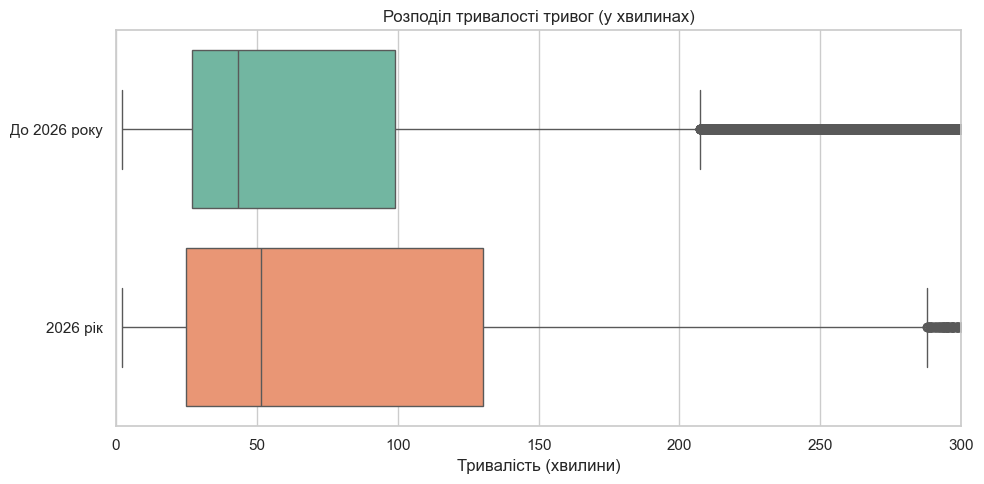


--- 4. Часова динаміка та регулярність (Нормалізована) ---


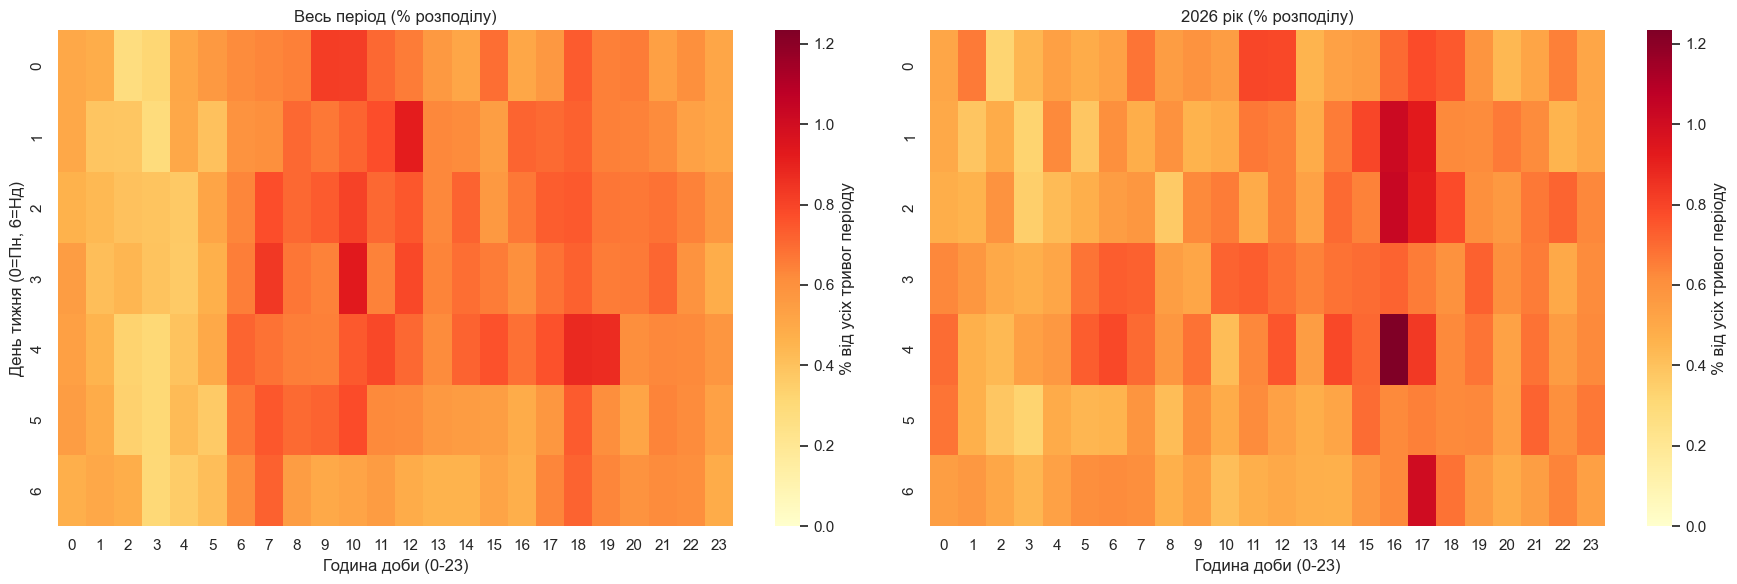

In [9]:
analyze_durations(df_merged_oblasts)
analyze_temporal_dynamics(df_merged_oblasts)